In [244]:
#  Сравниваем иерархии, полученные разными методами

In [245]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from functools import reduce
from scipy.stats import spearmanr, pearsonr
from typing import Dict, Tuple, Optional, List
from math import ceil


from analysis.regression import compute_deltas
from utils.utils import load_csv_files_from_folder
from utils.countryconverter import convert_country_df

In [246]:
BASIC_PROCESSED_POWER_DATA_DIR = "../data/basic_preprocessed/power/"
OUTPUT_DIR = "../output/pairwise/"

In [247]:
power_dfs = load_csv_files_from_folder(BASIC_PROCESSED_POWER_DATA_DIR)
#predictor_dfs = load_csv_files_from_folder(BASIC_PROCESSED_PREDICTORS_DATA_DIR)

In [248]:
translation_df = power_dfs['gpi'].merge(convert_country_df(power_dfs['gpi'], 'country', standard_to_convert='STATE_ru',print_convertions=False), how='left', left_index=True, right_index=True)[['country_x', 'country_y']].drop_duplicates()

In [249]:
translation_dict = translation_df.set_index('country_x').to_dict()['country_y']

### Functions

In [250]:
def plot_corr_pval_n(corr_result: pd.DataFrame,
                     pval_result: pd.DataFrame,
                     n_result: pd.DataFrame,
                     figsize: tuple = (18, 18),
                     savename: str = 'pairwise_spearman'
                    ) -> None:
    """
    Строит три тепловые карты одну под другой:
    1. Коэффициенты корреляции Спирмена (с аннотациями значений).
    2. P-value, отображаемые в виде звёздочек значимости:
       *** : p < 0.001, ** : p < 0.01, * : p < 0.05, иначе пусто.
    3. Количество наблюдений (только число).

    Ячейки, соответствующие корреляции исходного показателя со своим же лагом
    (например, 'X' со 'X_delta1'), скрываются маской.
    Полностью пустые строки и столбцы (все значения NaN) удаляются.

    Параметры
    ----------
    corr_result : pd.DataFrame
        Матрица коэффициентов корреляции.
    pval_result : pd.DataFrame
        Матрица p-value тех же размеров.
    n_result : pd.DataFrame
        Матрица количества наблюдений тех же размеров.
    figsize : tuple, optional
        Размер всей фигуры (ширина, высота) в дюймах. По умолчанию (18, 18).
    """
    # Удаляем полностью пустые строки и столбцы (на основе corr_result)
    rows_to_drop = corr_result.index[corr_result.isna().all(axis=1)]
    cols_to_drop = corr_result.columns[corr_result.isna().all(axis=0)]

    corr_result = corr_result.drop(index=rows_to_drop, columns=cols_to_drop)
    pval_result = pval_result.drop(index=rows_to_drop, columns=cols_to_drop)
    n_result = n_result.drop(index=rows_to_drop, columns=cols_to_drop)

    # Создаём маску для собственных лагов
    mask = pd.DataFrame(False, index=corr_result.index, columns=corr_result.columns)
    for idx in corr_result.index:
        for col in corr_result.columns:
            if col.startswith(f'{idx}_delta'):
                mask.loc[idx, col] = True

    # Готовим аннотации для p-value (звёздочки)
    pval_annot = pval_result.astype(object)
    for i in pval_result.index:
        for j in pval_result.columns:
            p = pval_result.loc[i, j]
            if pd.isna(p):
                pval_annot.loc[i, j] = ''
            elif p < 0.001:
                pval_annot.loc[i, j] = '***'
            elif p < 0.01:
                pval_annot.loc[i, j] = '**'
            elif p < 0.05:
                pval_annot.loc[i, j] = '*'
            else:
                pval_annot.loc[i, j] = ''

    # Готовим аннотации для n (только числа, без "n=")
    n_annot = n_result.astype(object)
    for i in n_result.index:
        for j in n_result.columns:
            val = n_result.loc[i, j]
            if pd.isna(val):
                n_annot.loc[i, j] = ''
            else:
                n_annot.loc[i, j] = str(int(val))

    # Создаём фигуру с тремя подграфиками
    fig, axes = plt.subplots(3, 1, figsize=figsize)

    # 1) Корреляции
    sns.heatmap(corr_result, annot=True, fmt=".2f", cmap='coolwarm',
                mask=mask, cbar=True, ax=axes[0], linewidths=0.5)
    axes[0].set_title('Попарная корреляция Спирмена')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

    # 2) P-value со звёздочками
    sns.heatmap(pval_result, annot=pval_annot, fmt='', cmap='coolwarm',
                mask=mask, cbar=True, ax=axes[1], linewidths=0.5)
    axes[1].set_title('P-значение (уровень значимости)')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)

    # 3) Количество наблюдений
    sns.heatmap(n_result, annot=n_annot, fmt='', cmap='viridis',
                mask=mask, cbar=True, ax=axes[2], linewidths=0.5)
    axes[2].set_title('Число наблюдений')
    axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha='right')
    axes[2].set_yticklabels(axes[2].get_yticklabels(), rotation=0)

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}{savename}.png", dpi=350)
    plt.show()


In [251]:
def get_mean_abs(rs, horizon=None):
    mean_abs = rs.unstack().dropna()[rs.unstack().dropna()<1].abs().mean()
    print(f"Среднее значение модулей с горизонтом {horizon} = {mean_abs}")
    return mean_abs

In [252]:
def compute_spearman_corr(
    power_dfs: Dict[str, pd.DataFrame],
    create_lags: bool = True
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Вычисляет корреляционную матрицу Спирмена для набора DataFrame'ов.

    Параметры
    ----------
    power_dfs : dict
        Словарь, где ключ — имя переменной, значение — DataFrame с колонками
        'country', 'year', 'value' (и, возможно, 'indicator', который игнорируется).
    create_lags : bool, default=True
        Если True, для каждой переменной добавляются лаговые колонки (shift 1, 2, 3)
        внутри каждой страны с именами вида "<variable>_delta1", "<variable>_delta2" и т.д.
        Если False, лаги не создаются.

    Возвращает
    ----------
    corr_df : pd.DataFrame
        Матрица коэффициентов корреляции Спирмена. Строки — только исходные переменные
        (без суффиксов лагов), столбцы — все переменные (включая лаги, если create_lags=True).
    pval_df : pd.DataFrame
        Матрица p-value для соответствующих корреляций (двусторонний тест).
    n_df : pd.DataFrame
        Матрица количества наблюдений (попарно непустых значений), использованных
        для расчёта каждой корреляции.
    """
    # 1. Отбираем DataFrame'ы без колонки 'indicator' и переименовываем value
    filtered = {}
    for name, data in power_dfs.items():
        if 'indicator' not in data.columns:
            filtered[name] = data[['country', 'year', 'value']].rename(columns={'value': name})

    if not filtered:
        # Если нет подходящих DataFrame, возвращаем пустые матрицы
        empty = pd.DataFrame()
        return empty, empty, empty

    # 2. Объединяем все данные в одну таблицу, при необходимости добавляем лаги
    merged = None
    for name, data in filtered.items():
        data = data.sort_values(['country', 'year'])
        if create_lags:
            for lag in [1, 2, 3]:
                data[f'{name}_delta{lag}'] = data.groupby('country')[name].shift(lag)
        if merged is None:
            merged = data
        else:
            merged = merged.merge(data, on=['country', 'year'], how='outer')

    # Все колонки с переменными (исключая служебные country, year)
    var_cols = [col for col in merged.columns if col not in ['country', 'year']]

    # 3. Инициализируем матрицы для корреляций, p-value и числа наблюдений
    corr_matrix = pd.DataFrame(index=var_cols, columns=var_cols, dtype=float)
    pval_matrix = pd.DataFrame(index=var_cols, columns=var_cols, dtype=float)
    n_matrix = pd.DataFrame(index=var_cols, columns=var_cols, dtype=int)

    # 4. Попарно вычисляем корреляцию Спирмена с p-value и количеством наблюдений
    for i, col1 in enumerate(var_cols):
        for j, col2 in enumerate(var_cols):
            if i == j:
                # Диагональ: корреляция = 1, p-value = 0 (если данные есть), n = число непустых
                corr_matrix.loc[col1, col2] = 1.0 if merged[col1].notna().any() else np.nan
                pval_matrix.loc[col1, col2] = 0.0 if merged[col1].notna().any() else np.nan
                n_matrix.loc[col1, col2] = merged[col1].notna().sum()
            else:
                subset = merged[[col1, col2]].dropna()
                n = len(subset)
                if n < 3:  # слишком мало точек для осмысленной корреляции
                    corr_matrix.loc[col1, col2] = np.nan
                    pval_matrix.loc[col1, col2] = np.nan
                    n_matrix.loc[col1, col2] = n
                else:
                    corr_val, p_val = spearmanr(subset[col1], subset[col2])
                    corr_matrix.loc[col1, col2] = corr_val
                    pval_matrix.loc[col1, col2] = p_val
                    n_matrix.loc[col1, col2] = n

    # 5. Определяем исходные колонки (без суффиксов лагов)
    if create_lags:
        original_cols = [
            col for col in var_cols
            if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
        ]
    else:
        original_cols = var_cols.copy()

    # 6. Выбираем строки только для исходных переменных
    corr_result = corr_matrix.loc[original_cols, :]
    pval_result = pval_matrix.loc[original_cols, :]
    n_result = n_matrix.loc[original_cols, :]

    return corr_result, pval_result, n_result

In [272]:
def yearly_pairwise_correlations(
    power_dfs: Dict[str, pd.DataFrame],
    method: str = 'spearman',
    min_obs: int = 3,
    plot: bool = True,
    figsize: Tuple[int, int] = (12, 6),
    legend_ncols: int = 2,
    highlight_net: bool = True,
    highlight_stroke_color: str = 'white',
    highlight_stroke_width: float = 3.0
) -> pd.DataFrame:
    """
    Вычисляет попарные корреляции между переменными для каждого года
    и опционально строит графики динамики.

    Пары, содержащие в названии 'net', выделяются обводкой (контуром) вокруг линии.

    Параметры
    ----------
    power_dfs : dict
        Словарь с DataFrame, каждый содержит колонки 'country', 'year', 'value'.
    method : str, optional
        'spearman' (по умолчанию) или 'pearson'.
    min_obs : int, optional
        Минимальное количество наблюдений для расчёта корреляции.
    plot : bool, optional
        Если True, строит графики.
    figsize : tuple, optional
        Размер фигуры для общего графика (при количестве пар > 9).
    legend_ncols : int, optional
        Количество столбцов в легенде на общем графике.
    highlight_net : bool, optional
        Если True, пары с 'net' в названии выделяются обводкой.
    highlight_stroke_color : str, optional
        Цвет обводки.
    highlight_stroke_width : float, optional
        Толщина обводки.

    Возвращает
    ----------
    results : pd.DataFrame
        Таблица с колонками: 'year', 'var1', 'var2', 'corr', 'p_value', 'n'.
    """
    # 1. Отбираем подходящие DataFrame
    filtered = {}
    for name, df in power_dfs.items():
        if 'indicator' not in df.columns:
            filtered[name] = df[['country', 'year', 'value']].rename(
                columns={'value': name}
            )

    if not filtered:
        return pd.DataFrame(columns=['year', 'var1', 'var2', 'corr', 'p_value', 'n'])

    # 2. Объединяем все переменные
    merged = None
    for name, df in filtered.items():
        if merged is None:
            merged = df
        else:
            merged = merged.merge(df, on=['country', 'year'], how='outer')

    var_names = [col for col in merged.columns if col not in ['country', 'year']]

    # 3. Группируем по годам и считаем корреляции
    results_list = []
    for year, group in merged.groupby('year'):
        data_year = group[var_names].dropna(how='all')
        if len(data_year) < min_obs:
            continue

        for i, var1 in enumerate(var_names):
            for var2 in var_names[i+1:]:
                pair = data_year[[var1, var2]].dropna()
                n = len(pair)
                if n < min_obs:
                    continue

                if method.lower() == 'spearman':
                    corr, p_val = spearmanr(pair[var1], pair[var2])
                elif method.lower() == 'pearson':
                    corr, p_val = pearsonr(pair[var1], pair[var2])
                else:
                    raise ValueError("method должен быть 'spearman' или 'pearson'")

                if not np.isnan(corr):
                    results_list.append({
                        'year': year,
                        'var1': var1,
                        'var2': var2,
                        'corr': corr,
                        'p_value': p_val,
                        'n': n
                    })

    results = pd.DataFrame(results_list)

    # 4. Построение графиков
    if plot and not results.empty:
        # Создаём подпись пары (отсортированные имена)
        results['pair'] = results.apply(
            lambda row: ' & '.join(sorted([row['var1'], row['var2']])),
            axis=1
        )
        unique_pairs = sorted(results['pair'].unique())
        n_pairs = len(unique_pairs)

        # Глобальный минимум для нижней границы графика
        global_min = results['corr'].min()

        # Функция проверки, содержит ли пара 'net'
        def is_net_pair(pair_name: str) -> bool:
            return 'net' in pair_name.lower()

        # Эффект обводки
        stroke_effect = pe.withStroke(
            linewidth=highlight_stroke_width,
            foreground=highlight_stroke_color
        )

        if n_pairs <= 9:
            # Несколько отдельных подграфиков
            ncols = 3
            nrows = int(np.ceil(n_pairs / ncols))
            fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4*nrows))
            if n_pairs == 1:
                axes = [axes]
            else:
                axes = axes.flatten()

            for ax, pair_name in zip(axes, unique_pairs):
                subset = results[results['pair'] == pair_name]
                pair_min = subset['corr'].min()

                line = ax.plot(subset['year'], subset['corr'], marker='o',
                               linewidth=1.5, linestyle='-')

                if highlight_net and is_net_pair(pair_name):
                    line[0].set_path_effects([stroke_effect])

                ax.set_title(pair_name)
                ax.set_xlabel('Год')
                ax.set_ylabel('Корреляция')
                ax.grid(True, alpha=0.3)
                ax.set_ylim(pair_min - 0.2, 1.05)

            for j in range(n_pairs, len(axes)):
                axes[j].axis('off')
            plt.tight_layout()
            plt.show()
        else:
            # Общий график со множеством пар
            plt.figure(figsize=figsize)
            ax = sns.lineplot(data=results, x='year', y='corr', hue='pair', marker='o')
            plt.title('Динамика попарных корреляций по годам')
            plt.xlabel('Год')
            plt.ylabel('Корреляция')
            plt.ylim(global_min - 0.2, 1.05)

            if highlight_net:
                # Применяем обводку к линиям, содержащим 'net'
                for line in ax.lines:
                    label = line.get_label()
                    if 'net' in label.lower():
                        line.set_path_effects([stroke_effect])

            plt.legend(
                bbox_to_anchor=(1.05, 1),
                loc='upper left',
                ncol=legend_ncols
            )
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.savefig(f'{OUTPUT_DIR}yearly_pairvise.png', dpi=350)
            plt.show()

    if 'pair' in results.columns:
        results = results.drop(columns='pair')

    return results

In [254]:
power_dfs.keys()

dict_keys(['athlas', 'gpi', 'cinc', 'gdp', 'net_subsystem', 'net', 'ihes', 'ihes_roles', 'ihes_new_roles', 'gdp_beckley', 'gdp_beckley_ppp'])

In [270]:
def plot_top_countries_metrics(
    data_dict,
    metrics=None,
    top_n=10,
    figsize=(15, 10),
    sharex=True,
    sort_by_last_year=True,
    cmap_name='tab10'
):
    """
    Строит сетку линейных графиков (small multiples) для топ-N стран по каждой метрике.

    Параметры
    ----------
    data_dict : dict
        Словарь, где ключи — названия метрик, значения — DataFrame с колонками
        'country', 'year', 'value'.
    metrics : list of str, optional
        Список метрик для отображения. Если None, используются все ключи data_dict.
    top_n : int, default=10
        Количество стран для отображения (топ-N по значению в последний доступный год).
    figsize : tuple, default=(15, 10)
        Размер всей фигуры.
    sharex : bool, default=True
        Использовать ли общую ось X для всех панелей.
    sort_by_last_year : bool, default=True
        Если True, топ-N определяется по значению в последний год, присутствующий в данных.
        Если False, используется среднее значение за весь период.
    cmap_name : str, default='tab10'
        Название цветовой карты matplotlib для назначения цветов странам.

    Возвращает
    -------
    fig, axes : matplotlib figure and axes array
    """
    # Определяем список метрик
    if metrics is None:
        metrics = list(data_dict.keys())
    n_metrics = len(metrics)

    # Вычисляем размер сетки: стараемся сделать приблизительно квадратной
    ncols = min(3, n_metrics)  # максимум 3 колонки для читаемости
    nrows = ceil(n_metrics / ncols)

    # Создаём фигуру и оси
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=sharex)
    # Преобразуем axes в одномерный массив для удобства итерации
    if n_metrics == 1:
        axes = np.array([axes])
    axes_flat = axes.flatten()

    # 1. Собираем все страны, которые попадают в топ-N хотя бы по одной метрике
    top_countries_all = set()
    for metric in metrics:
        df = data_dict[metric]
        # Определяем последний год в данных по этой метрике
        last_year = df['year'].max()
        if sort_by_last_year:
            # Сортировка по значению в последний год
            top_df = df[df['year'] == last_year].nlargest(top_n, 'value')
        else:
            # Альтернатива: по среднему значению за все годы
            mean_df = df.groupby('country')['value'].mean().reset_index()
            top_df = mean_df.nlargest(top_n, 'value')
        top_countries_all.update(top_df['country'].tolist())

    # Сортируем страны для стабильного порядка в легенде (по алфавиту)
    top_countries_all = sorted(top_countries_all)

    # 2. Назначаем цвета странам
    cmap = plt.get_cmap(cmap_name)
    colors = {country: cmap(i % cmap.N) for i, country in enumerate(top_countries_all)}

    # 3. Строим графики для каждой метрики
    for ax, metric in zip(axes_flat, metrics):
        df = data_dict[metric]
        # Определяем топ-N стран для этой конкретной метрики (чтобы отображать только их)
        last_year = df['year'].max()
        if sort_by_last_year:
            top_df = df[df['year'] == last_year].nlargest(top_n, 'value')
        else:
            mean_df = df.groupby('country')['value'].mean().reset_index()
            top_df = mean_df.nlargest(top_n, 'value')
        top_countries_metric = top_df['country'].tolist()

        for country in top_countries_metric:
            country_df = df[df['country'] == country].sort_values('year')
            ax.plot(country_df['year'], country_df['value'],
                    color=colors[country], label=country, linewidth=1.5)
        ax.set_title(metric, fontsize=10)
        ax.set_xlabel('Год')
        ax.set_ylabel('Значение')
        ax.grid(True, linestyle=':', alpha=0.5)
        # Убираем индивидуальные легенды
        ax.legend().set_visible(False)

    # 4. Скрываем лишние пустые панели, если метрик меньше, чем ячеек сетки
    for ax in axes_flat[n_metrics:]:
        ax.set_visible(False)

    # 5. Создаём общую легенду из всех уникальных стран
    # Используем фиктивные линии с нужными цветами
    import matplotlib.lines as mlines
    legend_handles = [mlines.Line2D([], [], color=colors[country],
                                    marker='o', linestyle='-',
                                    markersize=5, label=translation_dict[country])
                      for country in top_countries_all]
    # Размещаем легенду справа от графиков
    fig.legend(handles=legend_handles, loc='center left',
               bbox_to_anchor=(0.86, 0.5), fontsize=9, frameon=False)

    # 6. Настраиваем отступы, освобождая место для легенды
    plt.subplots_adjust(right=0.85)
    # Если используется sharex, общая подпись оси X
    if sharex:
        fig.text(0.5, 0.02, 'Год', ha='center', fontsize=12)
    plt.savefig(f'{OUTPUT_DIR}comparison_basic.png', dpi=350)
    plt.show()
    return fig, axes


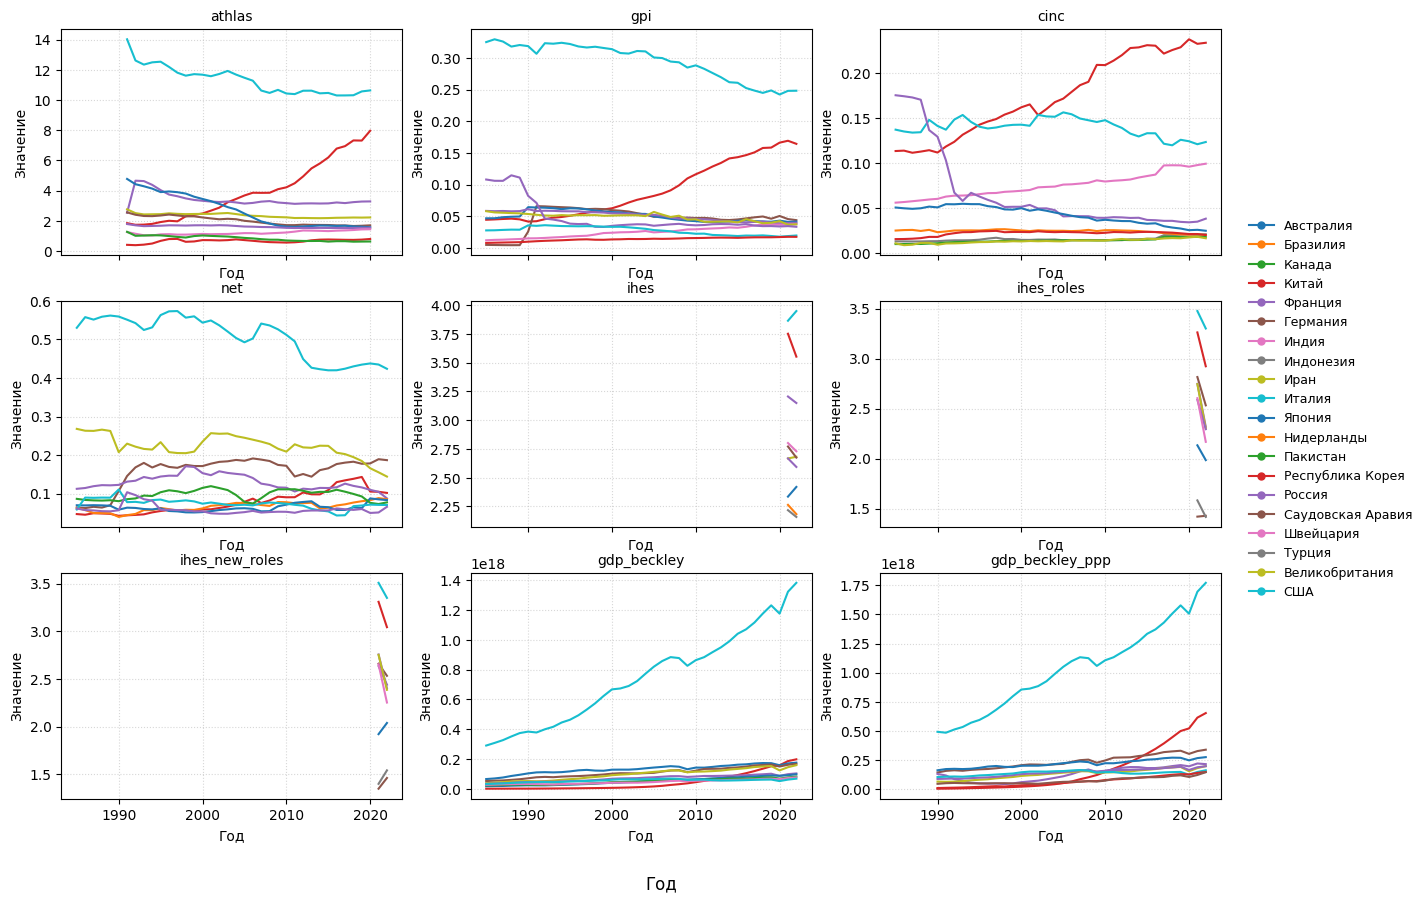

In [271]:
metrics_to_plot = ['athlas', 'gpi', 'cinc', 'net', 'ihes',
                   'ihes_roles', 'ihes_new_roles', 'gdp_beckley', 'gdp_beckley_ppp']
fig, axes = plot_top_countries_metrics(
    power_dfs,
    metrics=metrics_to_plot,
    top_n=10,
    figsize=(16, 10)
)


In [257]:
power_dfs['gpi'][power_dfs['gpi']['country']=='Republic of Korea']

,country,value,year
3276,Republic of Korea,0.007890,1985
3277,Republic of Korea,0.008267,1986
3278,Republic of Korea,0.008547,1987
3279,Republic of Korea,0.008822,1988
3280,Republic of Korea,0.009081,1989
3281,Republic of Korea,0.009878,1990
3282,Republic of Korea,0.010624,1991
3283,Republic of Korea,0.011241,1992
3284,Republic of Korea,0.011691,1993
3285,Republic of Korea,0.012117,1994


### Main

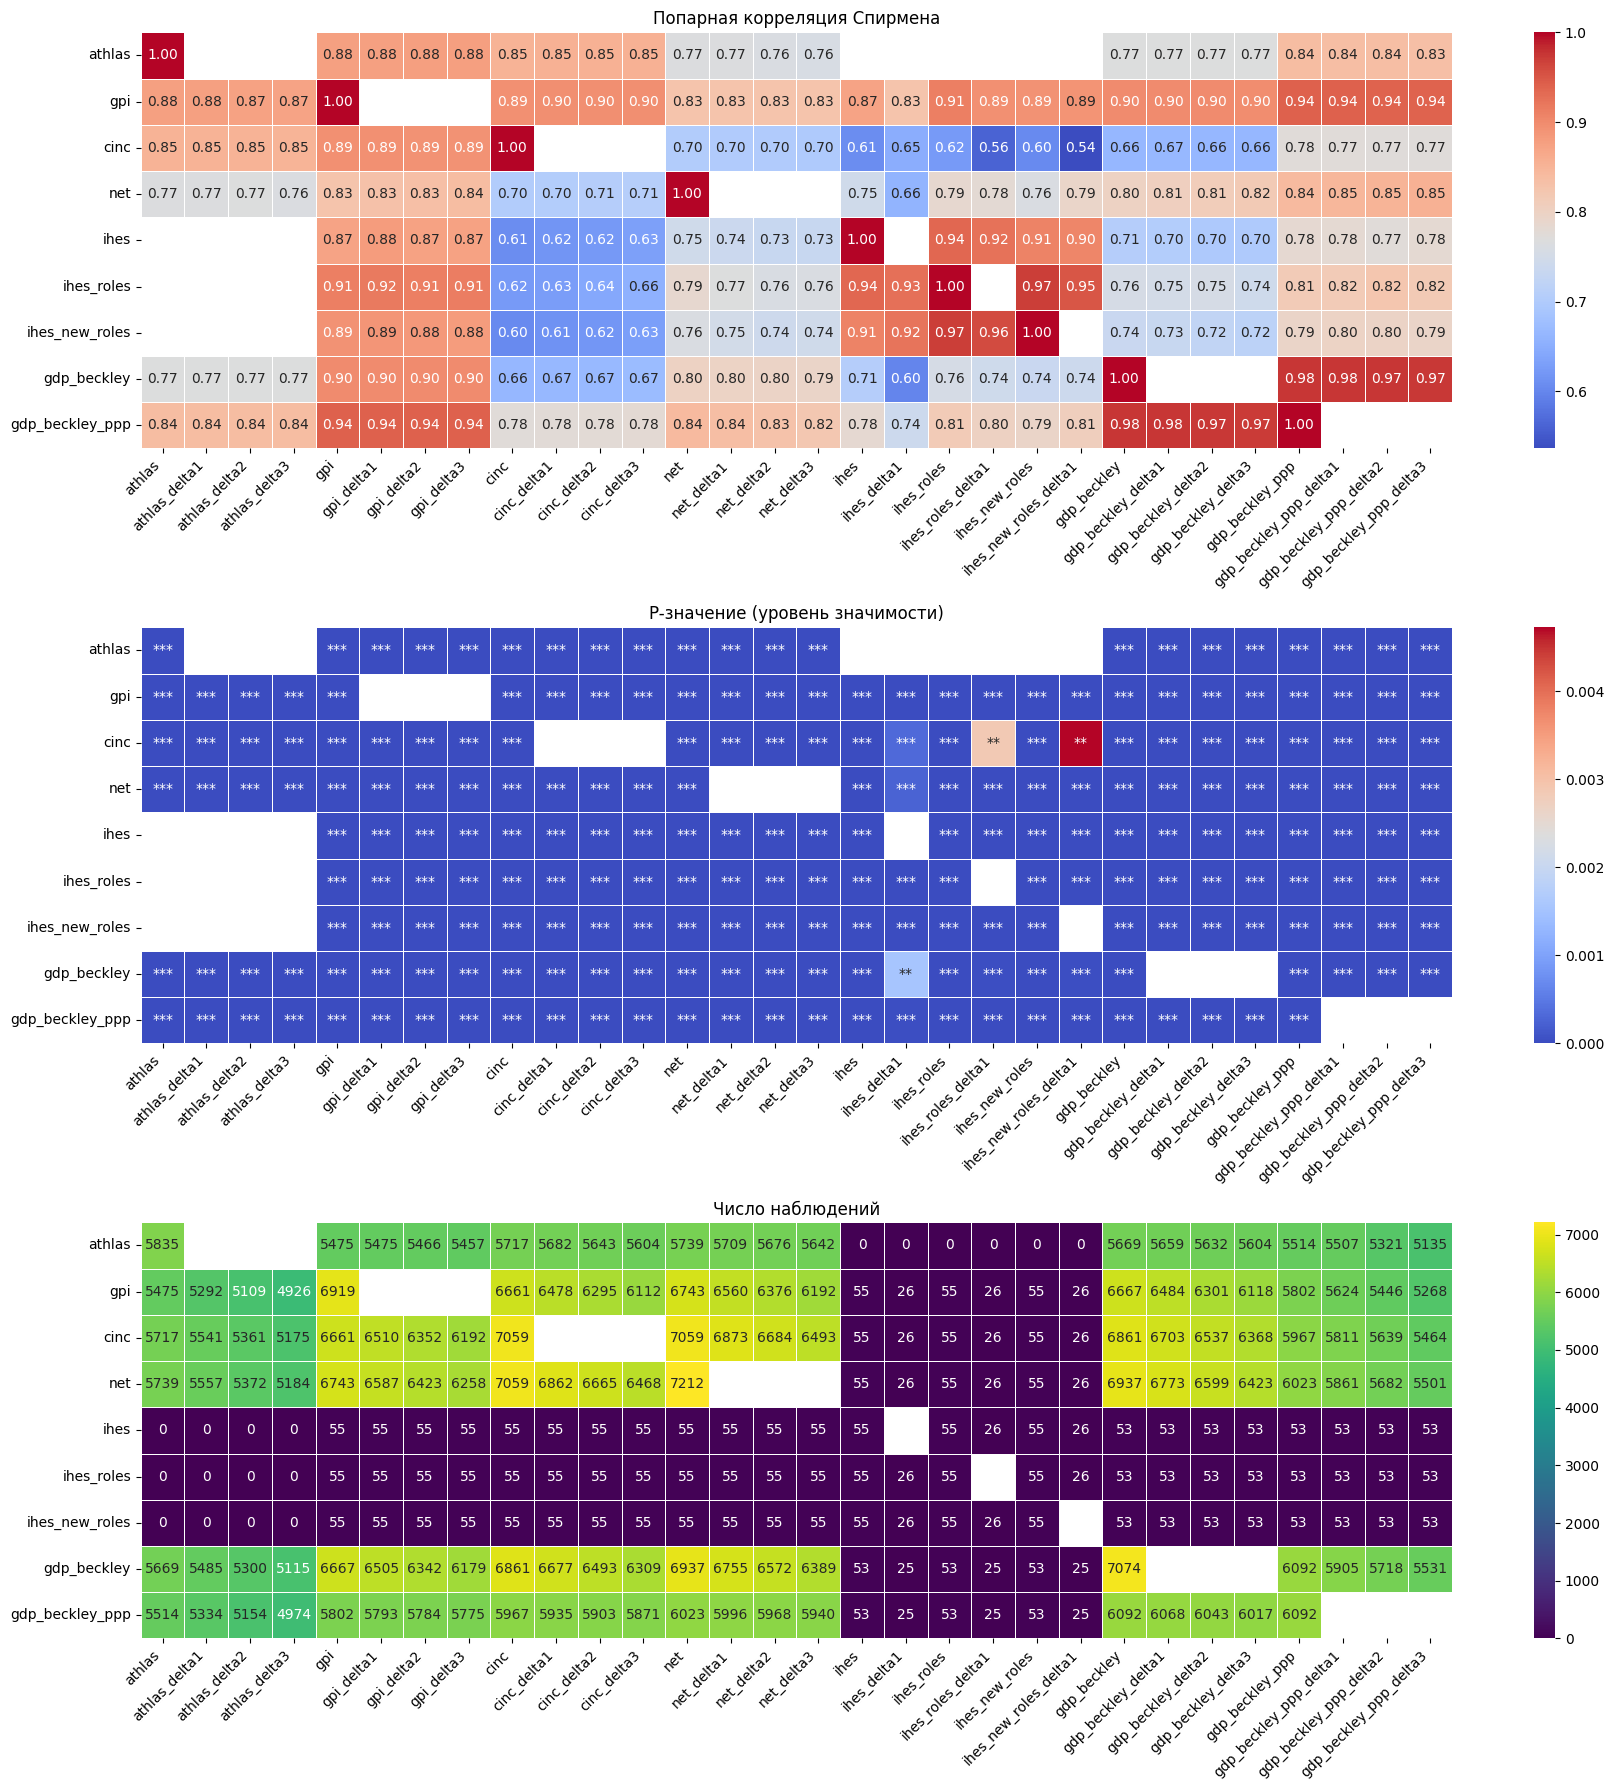

In [258]:
rs, pvalues, ns = compute_spearman_corr(power_dfs, create_lags=True)
plot_corr_pval_n(rs, pvalues, ns, savename='pairwise_spearman_deltas')

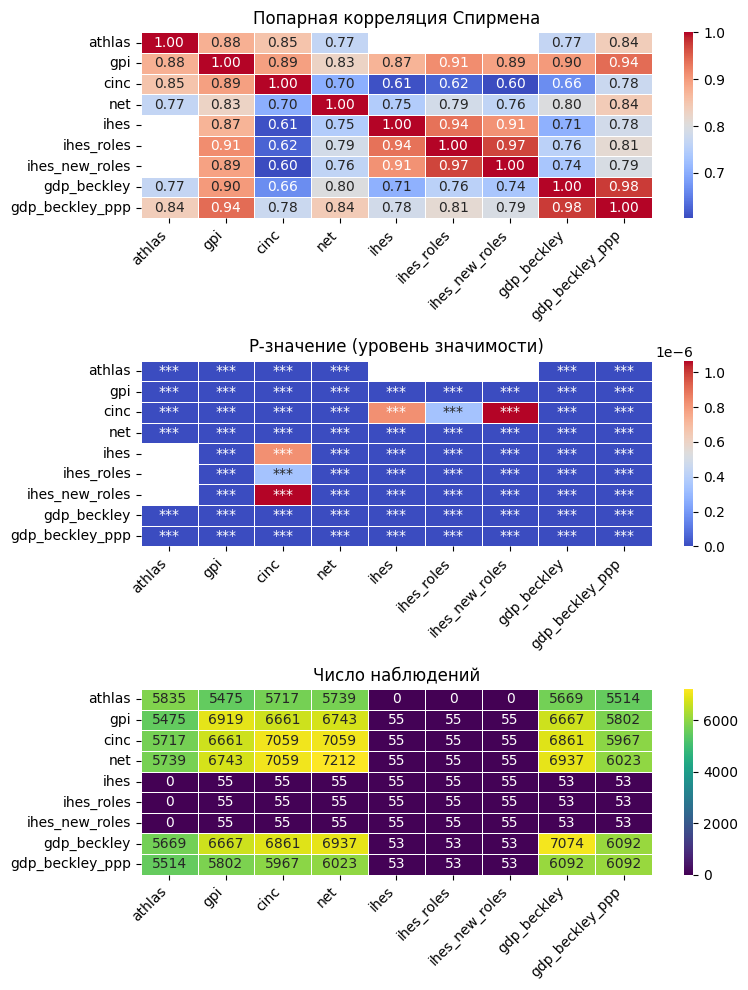

In [259]:
rs, pvalues, ns = compute_spearman_corr(power_dfs, create_lags=False)
plot_corr_pval_n(rs, pvalues, ns, savename='pairwise_spearman_nodeltas', figsize=(8,10))

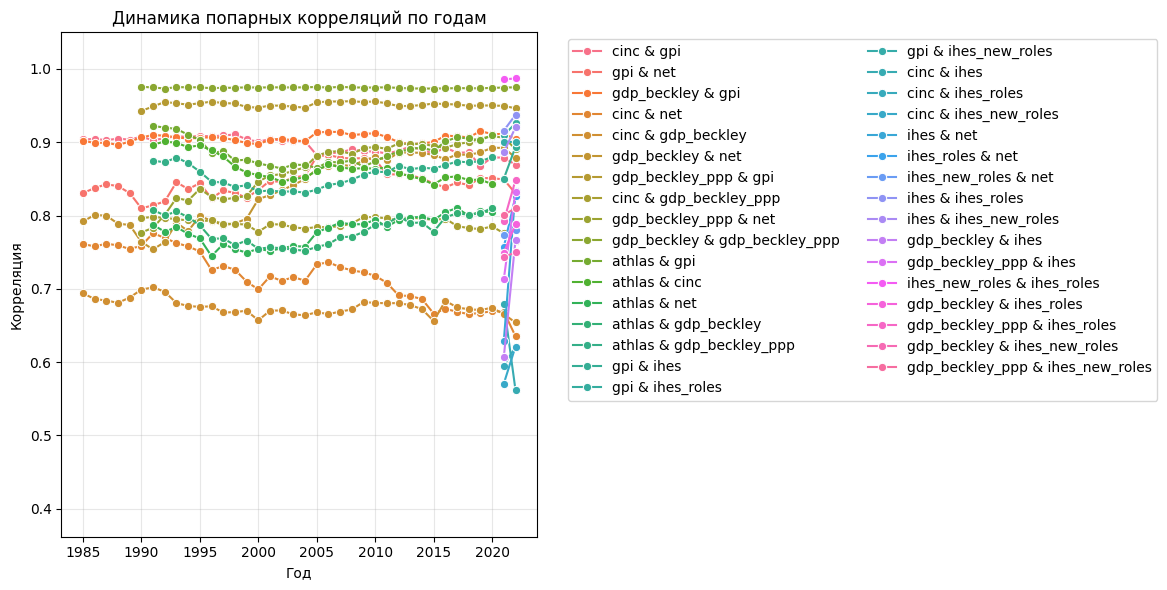

,year,var1,var2,corr,p_value,n
0,1985,gpi,cinc,0.903822,3.622729e-57,152
1,1985,gpi,net,0.830697,2.882278e-41,157
2,1985,gpi,gdp_beckley,0.902175,6.574832e-56,150
3,1985,cinc,net,0.761135,3.881533e-31,158
4,1985,cinc,gdp_beckley,0.693719,2.046008e-22,147
...,...,...,...,...,...,...
541,2022,ihes_roles,gdp_beckley,0.788177,6.362255e-07,28
542,2022,ihes_roles,gdp_beckley_ppp,0.848385,1.185134e-08,28
543,2022,ihes_new_roles,gdp_beckley,0.749863,4.357912e-06,28
544,2022,ihes_new_roles,gdp_beckley_ppp,0.810071,1.760676e-07,28


In [260]:
yearly_pairwise_correlations(power_dfs, highlight_net=False)

In [261]:
# Тут что-то не так. Слишком много n

In [262]:
deltas = dict()
horizon = 5
for cat in power_dfs:
    if 'indicator' in power_dfs[cat].columns:
        continue
    deltas[cat] = compute_deltas(power_dfs[cat],horizons=(horizon,)).rename({f'delta_{horizon}':'value'}, axis=1)

Среднее значение модулей с горизонтом 5 = 0.19456409282952167


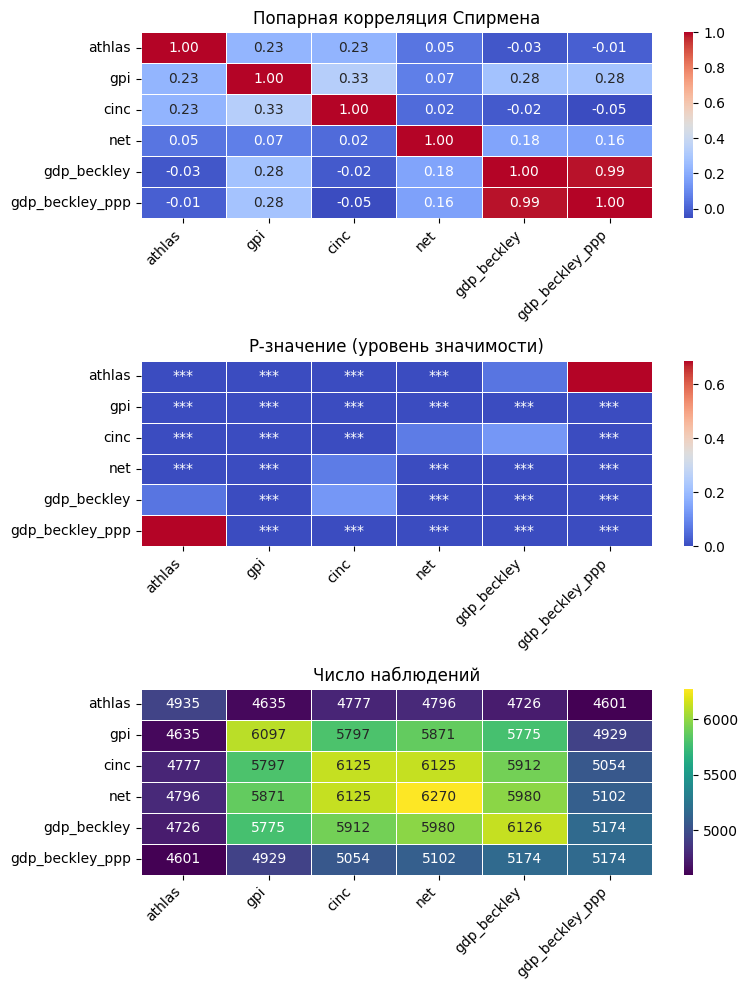

In [263]:
rs, pvalues, ns = compute_spearman_corr(deltas, create_lags=False)
get_mean_abs(rs, horizon)
plot_corr_pval_n(rs, pvalues, ns, savename=f'pairwise_spearman_of_delta_nodelta_horizon{horizon}', figsize=(8,10))

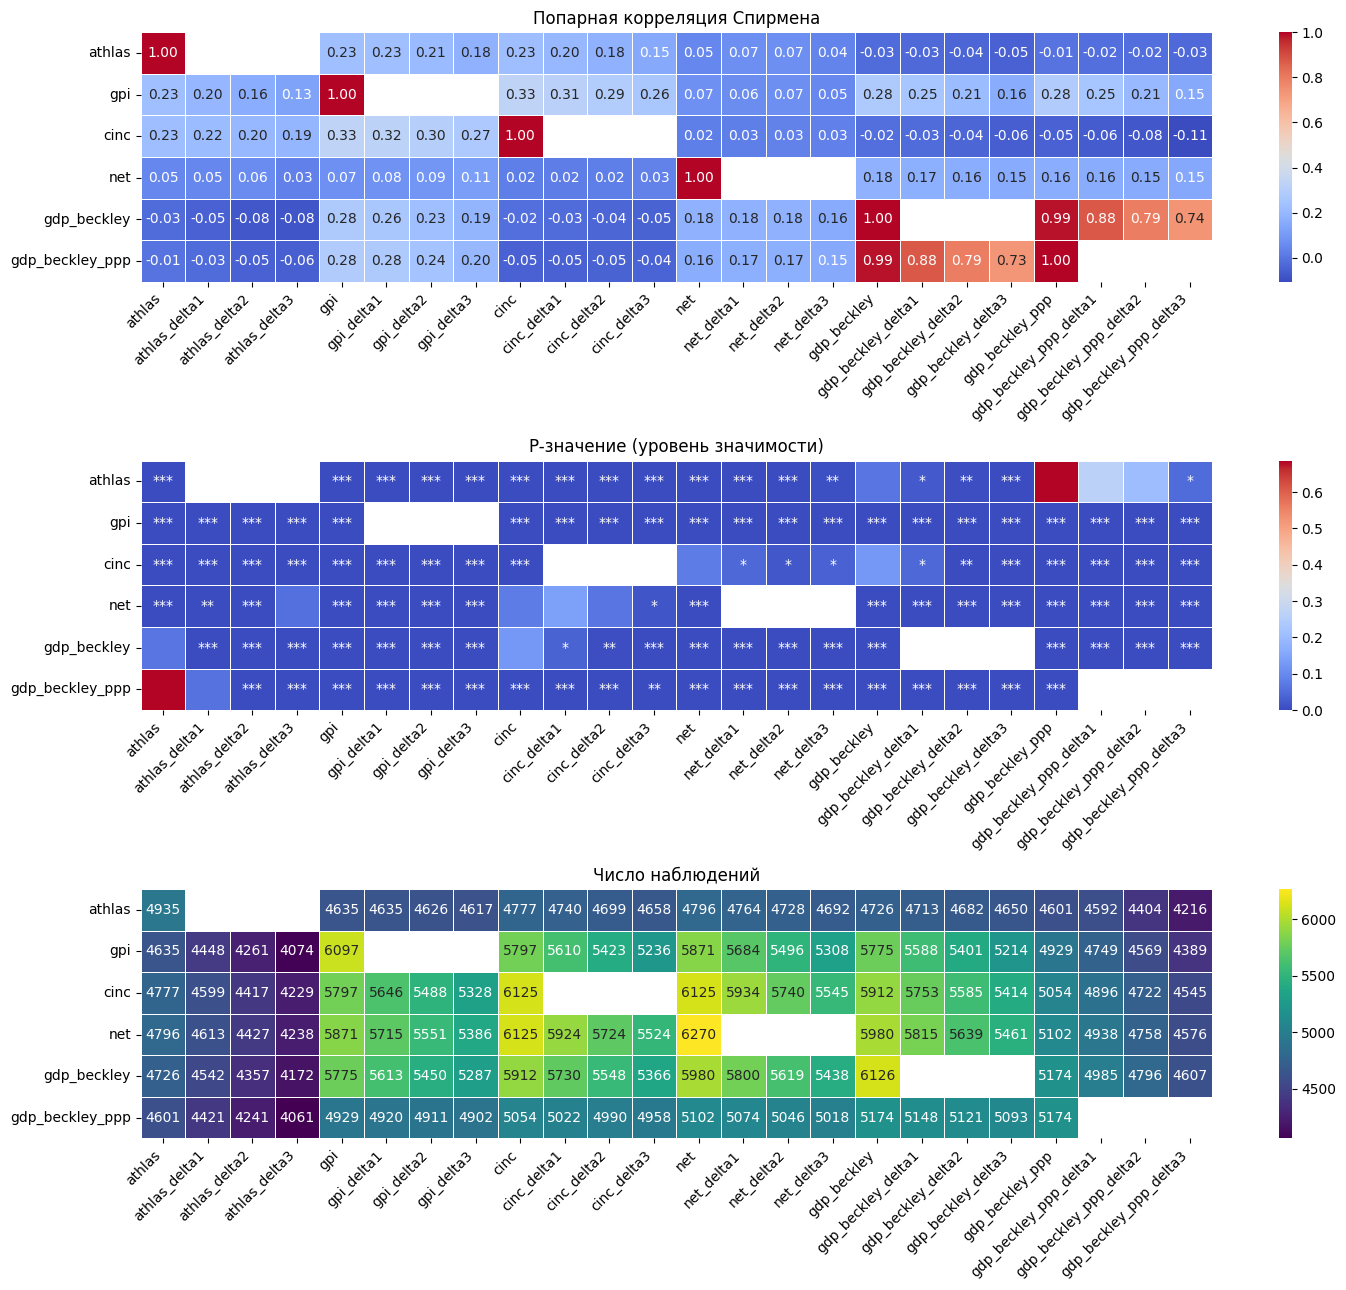

In [264]:
rs, pvalues, ns = compute_spearman_corr(deltas, create_lags=True)
plot_corr_pval_n(rs, pvalues, ns, savename=f'pairwise_spearman_of_delta_wdelta_horizon{horizon}', figsize=(15,13))

In [265]:
deltas = dict()
horizon = 1
for cat in power_dfs:
    if 'indicator' in power_dfs[cat].columns:
        continue
    deltas[cat] = compute_deltas(power_dfs[cat],horizons=(horizon,)).rename({f'delta_{horizon}':'value'}, axis=1)

Среднее значение модулей с горизонтом 1 = 0.14825806032432767


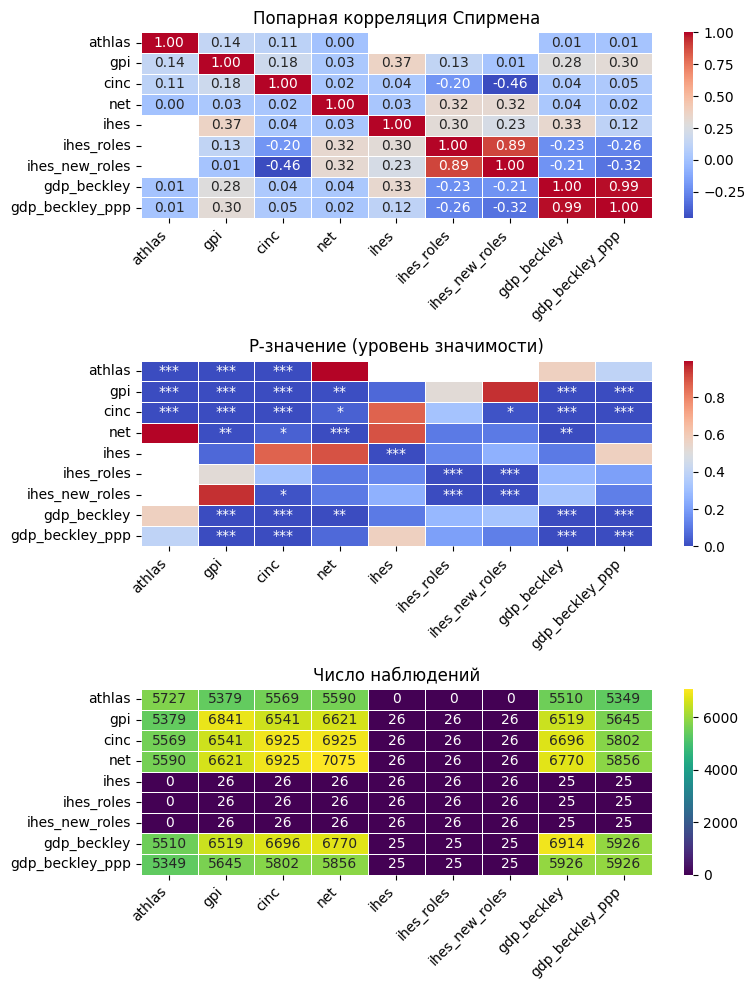

In [266]:
rs, pvalues, ns = compute_spearman_corr(deltas, create_lags=False)
get_mean_abs(rs.loc[(~rs.index.str.contains('ihes')),(~rs.columns.str.contains('ihes'))], horizon)
plot_corr_pval_n(rs, pvalues, ns, savename=f'pairwise_spearman_of_delta_nodelta_horizon{horizon}', figsize=(8,10))

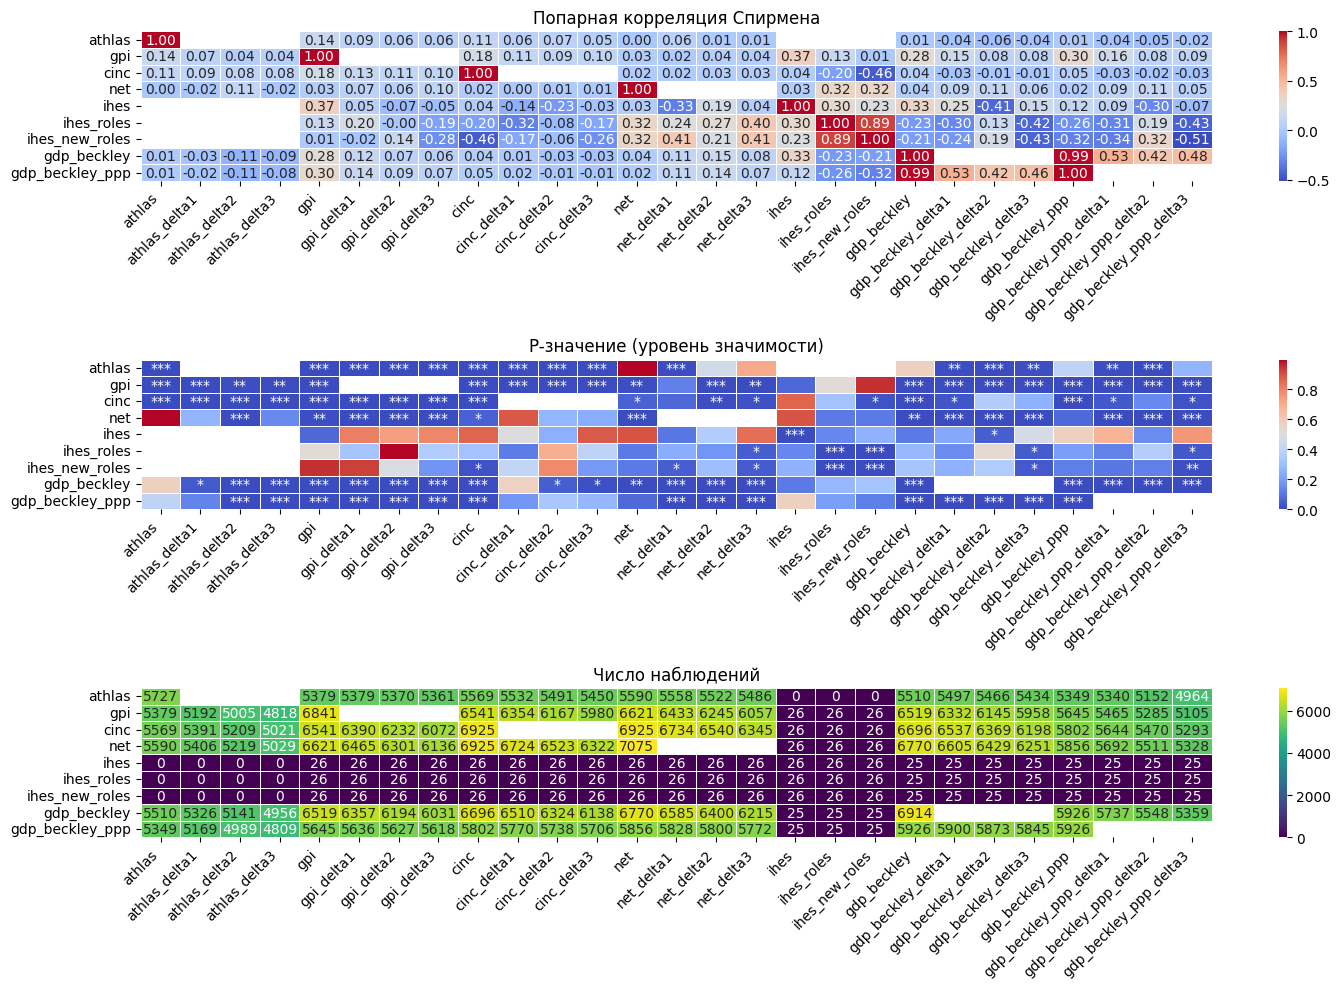

In [267]:
# почему это
rs, pvalues, ns = compute_spearman_corr(deltas, create_lags=True)
plot_corr_pval_n(rs, pvalues, ns, savename=f'pairwise_spearman_of_delta_wdelta_horizon{horizon}', figsize=(15,10))